# First trained citywide model: XGBoost

This **development experiment** uses January–February 2024: 1,440 hourly observations and 4,006,382 accepted ride starts. It does not change the final January 2024–December 2025 dataset or the full CityPulse AI scope. We reuse existing validated local outputs, including adjacent-archive contributions; no raw ETL or cloud operation runs here.

## Trees, boosting and XGBoost
A **decision tree** asks a sequence of questions, such as “was demand at this hour yesterday above 3,000?” The answers send a row to a leaf with a numerical prediction. Tree training chooses thresholds and leaf values that reduce prediction error.

**Gradient boosting** builds trees sequentially. Starting with a simple prediction, each new tree learns a correction guided by the current loss gradient. Under squared error, this behaves like learning the remaining prediction errors. The model adds these tree corrections, scaled by a learning rate. **XGBoost** implements this approach efficiently with regularization and tree-building optimizations. We use `XGBRegressor` on CPU with squared-error loss.

A **feature** is an input available at prediction time; the **target** is the ride count we want to predict. **Model parameters**—such as split thresholds and leaf values—are learned from training data. **Hyperparameters**—such as tree count, depth, learning rate and subsample fraction—are settings we choose before fitting.

References: [XGBoost's tree and boosting explanation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html), [Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html).

## Environment and imports
Use **CityPulse AI (.venv)**. Install the existing environment's forecasting extra with `python -m pip install -e '.[forecasting,notebooks,dev]'`. macOS also needs the OpenMP runtime (`libomp`); report compatibility issues before changing environments. This experiment uses the existing Python, not a replacement environment.

On this macOS environment, Homebrew could not install OpenMP. The installed scikit-learn wheel includes a compatible runtime. Before starting Jupyter or running tests, use:

```bash
export DYLD_LIBRARY_PATH="$PWD/.venv/lib/python3.14/site-packages/sklearn/.dylibs${DYLD_LIBRARY_PATH:+:$DYLD_LIBRARY_PATH}"
.venv/bin/python -m jupyter lab
```

This setting is inherited by the notebook kernel. It does not change Python versions or the project data.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import xgboost, sklearn, numpy, scipy
from IPython.display import display, Markdown
from citypulse_ai.forecasting.experiment import load_development_citywide, START, END
from citypulse_ai.forecasting.baselines import LOCAL_ZONE, evaluate_midnights
from citypulse_ai.forecasting.xgboost_model import (
    FEATURES, CONFIGURATIONS, VALIDATION_START, TEST_START,
    training_rows, run_xgboost_experiment, forecast_next_day,
)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
versions = {name: module.__version__ for name, module in [('xgboost', xgboost), ('sklearn', sklearn),
           ('numpy', numpy), ('scipy', scipy), ('pandas', pd)]}
display(versions)
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True})

Matplotlib is building the font cache; this may take a moment.


{'xgboost': '3.4.1',
 'sklearn': '1.9.1',
 'numpy': '2.5.3',
 'scipy': '1.18.1',
 'pandas': '3.0.6'}

## Reuse the reconciled target
The existing loader verifies hashes and duplicates and returns compact citywide counts. January includes 231 starts from February's archive; February includes 235 from March's archive. UTC keys are preserved; calendar features use America/New_York. Missing hours are not silently zero-filled.

In [2]:
citywide, provenance = load_development_citywide(ROOT / 'outputs/historical')
assert len(citywide) == 1440 and provenance['missing_citywide_hours'] == 0
assert int(citywide.ride_count.sum()) == 4006382
series = citywide.set_index('hour_start').ride_count
display(pd.Series(provenance['local_start_month_counts'], name='accepted_starts'))

2024-01    1886746
2024-02    2119636
Name: accepted_starts, dtype: int64

## Features must exist at midnight
For each next-day target hour we use its hour, weekday, weekend indicator, cyclic hour/weekday sine and cosine, and demand at target time minus 24 and 168 elapsed hours. Sine/cosine encodings put neighbouring points on a circle: hour 23 is close to hour 0, and Sunday is close to Monday.

At local midnight every requested lag is strictly before the issuance time. We do not use today's actual demand, future weather, rolling target averages or lag 1. The preceding completed hour is assumed available immediately; production delays require a separate policy. No DST transition occurs in this development window.

Training targets come **only from January**. Without December history, the first seven days lack lag 168 and are dropped. There is no future backfill. Metadata timestamps remain separate from the nine model input columns.

In [3]:
train, dropped = training_rows(series)
display(pd.DataFrame({'training_rows': [len(train)], 'dropped_warmup_rows': [dropped],
                      'first_target': [train.hour_start.min()], 'last_target': [train.hour_start.max()]}))
display(train[['origin', 'hour_start', *FEATURES, 'target']].head())
assert train.hour_start.lt(VALIDATION_START).all()
assert train.lag_24_source_hour.lt(train.origin).all()
assert train.lag_168_source_hour.lt(train.origin).all()

,training_rows,dropped_warmup_rows,first_target,last_target
0,576,168,2024-01-08 05:00:00+00:00,2024-02-01 04:00:00+00:00


,origin,hour_start,hour,weekday,is_weekend,hour_sin,hour_cos,weekday_sin,weekday_cos,lag_24,lag_168,target
0,2024-01-08 05:00:00+00:00,2024-01-08 05:00:00+00:00,0,0,0,0.000000,1.000000,0.0,1.0,487.0,1898.0,473.0
1,2024-01-08 05:00:00+00:00,2024-01-08 06:00:00+00:00,1,0,0,0.258819,0.965926,0.0,1.0,304.0,2329.0,252.0
2,2024-01-08 05:00:00+00:00,2024-01-08 07:00:00+00:00,2,0,0,0.500000,0.866025,0.0,1.0,262.0,1938.0,168.0
3,2024-01-08 05:00:00+00:00,2024-01-08 08:00:00+00:00,3,0,0,0.707107,0.707107,0.0,1.0,187.0,1098.0,137.0
4,2024-01-08 05:00:00+00:00,2024-01-08 09:00:00+00:00,4,0,0,0.866025,0.500000,0.0,1.0,123.0,655.0,204.0


## Four predefined configurations; validation selects one
We explore four fixed combinations of `n_estimators` (number of trees), `max_depth` (tree complexity), `learning_rate` (correction size), and `subsample` (fraction of training rows sampled for each tree). This is a small development search, not an exhaustive optimization.

Every candidate fits exactly the same January rows. Validation is February 1–14: 14 local-midnight origins and 336 target hours. Select the lowest pooled validation **MAE**; an exact tie keeps the first predefined configuration. Seed 42 and one CPU thread improve repeatability. There is no early stopping and no validation/test `eval_set`.

After selection, keep the January-trained model frozen. Test February 15–29 supplies 15 origins and 360 target hours. Test results never select or refit a candidate. Completed earlier February days become lag history at later origins, as in the baseline experiment; no within-day updates are permitted. Negative model predictions are clipped to zero under a rule fixed before evaluation.

In [4]:
display(pd.DataFrame(CONFIGURATIONS))
selected, predictions, xgb_metrics = run_xgboost_experiment(series)
display(selected.search_results.round(3))
display(selected.parameters)
assert selected.training_rows == len(train)
assert predictions.lag_24_source_hour.lt(predictions.origin).all()
assert predictions.lag_168_source_hour.lt(predictions.origin).all()

,n_estimators,max_depth,learning_rate,subsample
0,100,2,0.05,1.0
1,200,2,0.05,0.8
2,150,3,0.05,1.0
3,150,3,0.10,0.8


,configuration,n_estimators,max_depth,learning_rate,subsample,forecast_origins,target_hours,MAE,RMSE,WAPE_percent
0,0,100,2,0.05,1.0,14,336,838.889,1222.493,25.769
1,1,200,2,0.05,0.8,14,336,827.744,1226.391,25.427
2,2,150,3,0.05,1.0,14,336,782.443,1242.431,24.035
3,3,150,3,0.10,0.8,14,336,797.913,1278.097,24.510


{'n_estimators': 150,
 'max_depth': 3,
 'learning_rate': 0.05,
 'subsample': 1.0,
 'random_state': 42,
 'n_jobs': 1,
 'tree_method': 'hist',
 'objective': 'reg:squarederror',
 'eval_metric': 'mae',
 'importance_type': 'gain'}

## Compare with the existing seasonal baselines
MAE and RMSE measure error in rides/hour; RMSE penalizes large errors more. WAPE is total absolute error divided by total actual demand, multiplied by 100. We pool hourly errors across forecast blocks separately for validation and test. WAPE is undefined if total actual demand is zero.

The existing baseline implementation is reused, and every model is scored on the same targets and midnight origins.

In [5]:
baseline_predictions, baseline_metrics = [], []
for split, left, right in [('validation', VALIDATION_START, TEST_START), ('test', TEST_START, END)]:
    forecast, scores = evaluate_midnights(series, left, right)
    baseline_predictions.append(forecast.assign(split=split))
    baseline_metrics.append(scores.assign(split=split, model=scores.lag_hours.map({24: 'Lag 24', 168: 'Lag 168'})))
baselines = pd.concat(baseline_predictions, ignore_index=True)
comparison = pd.concat([pd.concat(baseline_metrics, ignore_index=True),
                        xgb_metrics.assign(model='XGBoost')], ignore_index=True)
comparison = comparison[['split', 'model', 'forecast_origins', 'target_hours', 'MAE', 'RMSE', 'WAPE_percent']]
display(comparison.round(3))
for split in ['validation', 'test']:
    rows = comparison[comparison.split.eq(split)].set_index('model')
    outcome = 'lower' if rows.loc['XGBoost', 'MAE'] < rows.loc[['Lag 24', 'Lag 168'], 'MAE'].min() else 'not lower'
    display(Markdown(f"**{split.title()}**: XGBoost MAE is {rows.loc['XGBoost', 'MAE']:.2f}, {outcome} than both baselines. "
                    "This is a measured comparison on this split, not a general performance guarantee."))

,split,model,forecast_origins,target_hours,MAE,RMSE,WAPE_percent
0,validation,Lag 24,14,336,908.146,1454.002,27.897
1,validation,Lag 168,14,336,715.628,1202.430,21.983
2,test,Lag 24,15,360,759.853,1199.061,26.666
3,test,Lag 168,15,360,948.014,1438.950,33.269
4,validation,XGBoost,14,336,782.443,1242.431,24.035
5,test,XGBoost,15,360,649.272,994.204,22.785


**Validation**: XGBoost MAE is 782.44, not lower than both baselines. This is a measured comparison on this split, not a general performance guarantee.

**Test**: XGBoost MAE is 649.27, lower than both baselines. This is a measured comparison on this split, not a general performance guarantee.

## Actual versus predicted
The plot shows the last test week, including leap day. Each predicted line connects independently issued next-day forecast blocks. We inspect peak-hour misses as well as the aggregate metrics.

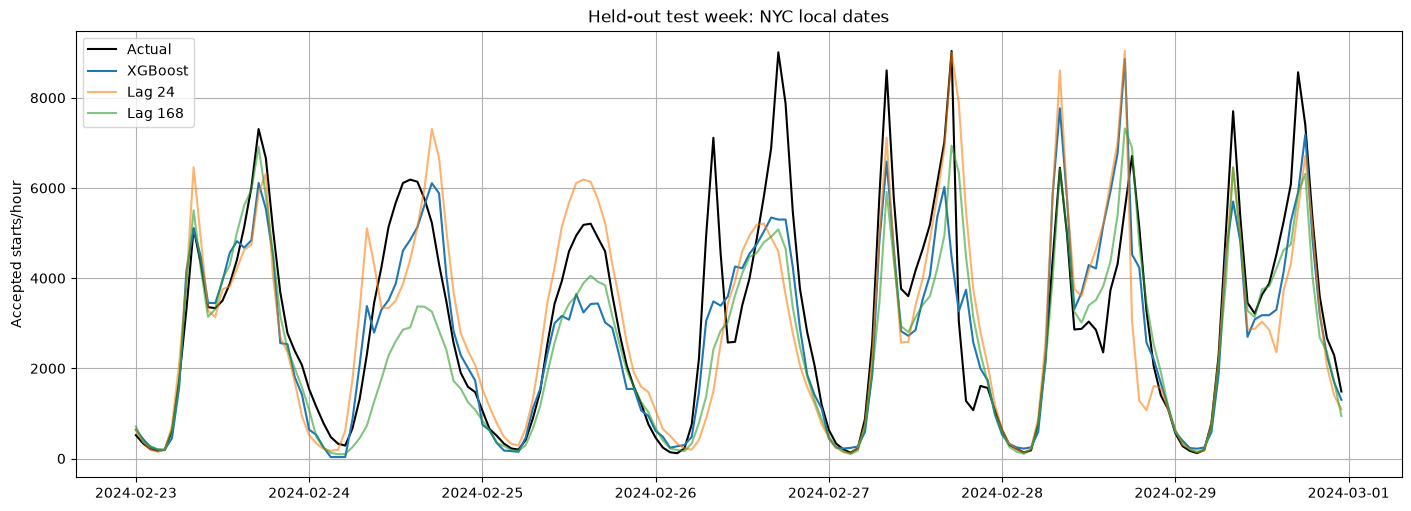

In [6]:
left = pd.Timestamp('2024-02-23', tz=LOCAL_ZONE)
week = predictions[predictions.split.eq('test') & predictions.hour_start.ge(left)]
fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
ax.plot(week.hour_start.dt.tz_convert(LOCAL_ZONE), week.actual, color='black', label='Actual')
ax.plot(week.hour_start.dt.tz_convert(LOCAL_ZONE), week.prediction, label='XGBoost')
for lag in (24, 168):
    rows = baselines[baselines.split.eq('test') & baselines.lag_hours.eq(lag) & baselines.hour_start.ge(left)]
    ax.plot(rows.hour_start.dt.tz_convert(LOCAL_ZONE), rows.prediction, alpha=0.6, label=f'Lag {lag}')
ax.set(title='Held-out test week: NYC local dates', ylabel='Accepted starts/hour')
ax.legend()
plt.show()

## Feature importance: useful, but not causal
The model reports normalized **gain importance**: features receive credit for reductions in training loss from tree splits. Calendar encodings and lags are correlated, so a low score does not mean a feature carries no information. Importance is not a causal effect, a test-set explanation or a stability guarantee. We do not use this chart to retune the model after seeing test results.

,normalized_gain
hour_cos,0.374640
lag_168,0.236618
hour,0.105606
lag_24,0.095174
hour_sin,0.086466
weekday,0.061327
weekday_cos,0.022142
weekday_sin,0.018027
is_weekend,0.000000


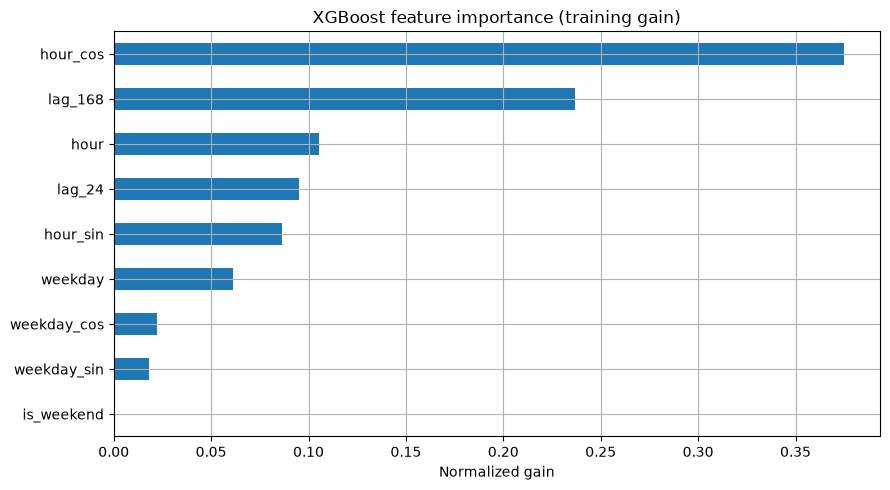

In [7]:
importance = pd.Series(selected.model.feature_importances_, index=FEATURES, name='normalized_gain').sort_values(ascending=False)
display(importance.to_frame())
importance.sort_values().plot.barh(title='XGBoost feature importance (training gain)', xlabel='Normalized gain', figsize=(9, 5))
plt.tight_layout()
plt.show()

## Example next-day forecast: March 1, issued at midnight
This produces 24 predictions using completed February history and the frozen January-trained model. No March actual counts are loaded or scored here. The example demonstrates issuance, not a new test or an improvement claim.

/var/folders/n5/f6xjtlr526zbr86__yns243m0000gn/T/ipykernel_42647/33828530.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(example_table[['NYC_target_hour', 'prediction']].round(2))


,NYC_target_hour,prediction
0,2024-03-01 00:00:00-05:00,599.75
1,2024-03-01 01:00:00-05:00,365.88
2,2024-03-01 02:00:00-05:00,254.80
3,2024-03-01 03:00:00-05:00,198.01
4,2024-03-01 04:00:00-05:00,198.01
5,2024-03-01 05:00:00-05:00,451.67
6,2024-03-01 06:00:00-05:00,1832.17
7,2024-03-01 07:00:00-05:00,4323.55
8,2024-03-01 08:00:00-05:00,5840.62
9,2024-03-01 09:00:00-05:00,4631.30


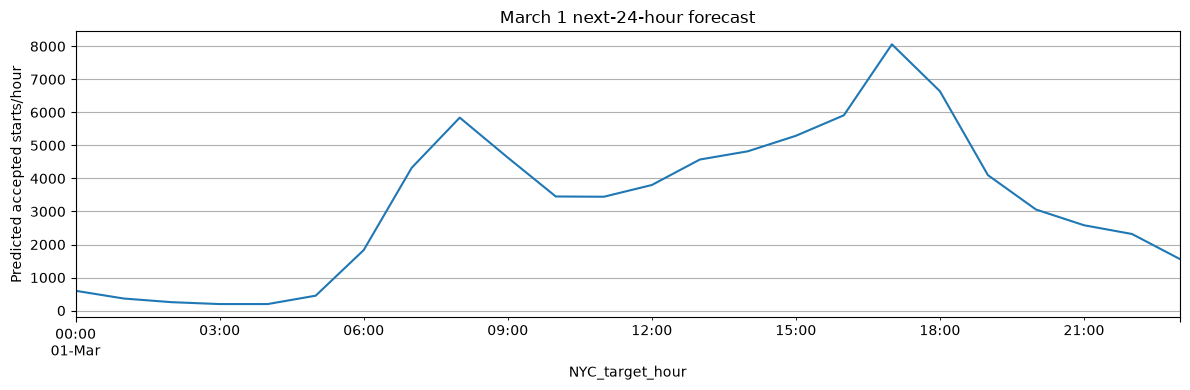

In [8]:
example = forecast_next_day(selected.model, series.loc[series.index < END], END)
example_table = example[['hour_start', 'prediction']].copy()
example_table['NYC_target_hour'] = example_table.hour_start.dt.tz_convert(LOCAL_ZONE)
display(example_table[['NYC_target_hour', 'prediction']].round(2))
ax = example_table.plot(x='NYC_target_hour', y='prediction', legend=False, title='March 1 next-24-hour forecast')
ax.set(ylabel='Predicted accepted starts/hour')
plt.tight_layout()
plt.show()

## Actual results and limitations
**Measured outcome:** validation MAE is 782.44: better than lag 24 (908.15), worse than lag 168 (715.63). Test MAE is 649.27, better than lag 24 (759.85) and lag 168 (948.01). The same ranking holds for RMSE and WAPE. The best validation configuration was 150 trees, depth 3, learning rate 0.05, subsample 1.0. The test plot still shows missed commute peaks; a lower average error does not mean every forecast hour improved. Selection uses validation only; test is reported once for the chosen model. Even if it wins here, this is a small winter-only experiment with only 576 training rows after lag warm-up and correlated forecast errors.

Tree models can overfit and generally cannot extrapolate beyond learned response patterns. Weather, holidays, station changes, reporting delay and unmet demand are not modelled. We make no statistical significance or final-model claim. The final 24-month plan is unchanged; these development hyperparameters should not be assumed optimal for that much larger dataset.

Re-running this notebook reproduces the development experiment from local validated outputs with a fixed seed. Exact results may vary across library/platform versions; installed versions and source hashes are recorded below.

In [9]:
experiment_record = {
    'development_only': True, 'versions': versions, 'provenance': provenance,
    'training_rows': selected.training_rows, 'dropped_training_rows': selected.dropped_training_rows,
    'selected_parameters': selected.parameters, 'search_results': selected.search_results.to_dict(orient='records'),
    'metrics': comparison.to_dict(orient='records'), 'feature_importance': importance.to_dict(),
    'example_next_day_forecast': example_table.assign(hour_start=example_table.hour_start.astype(str),
                                                   NYC_target_hour=example_table.NYC_target_hour.astype(str)).to_dict(orient='records'),
}
display({'selected_parameters': selected.parameters, 'training_rows': selected.training_rows,
         'source_manifest_sha256': provenance['manifest_sha256']})

# Save measured results to the ignored local outputs directory.
result_dir = ROOT / "outputs/phase3-xgboost-jan-feb-2024"
result_dir.mkdir(parents=True, exist_ok=True)
(result_dir / "experiment.json").write_text(json.dumps(experiment_record, indent=2, default=str) + "\n")


{'selected_parameters': {'n_estimators': 150,
  'max_depth': 3,
  'learning_rate': 0.05,
  'subsample': 1.0,
  'random_state': 42,
  'n_jobs': 1,
  'tree_method': 'hist',
  'objective': 'reg:squarederror',
  'eval_metric': 'mae',
  'importance_type': 'gain'},
 'training_rows': 576,
 'source_manifest_sha256': '6276e61cf63ebcf2c49da294f1a5f3cdd2bf85566e4276611f000f69c55050fa'}

9172